# Chapter 2: MDP Foundations — Case Study

## Value Iteration vs Policy Iteration on Grid Worlds

This notebook presents the polished Chapter 2 case study using helper modules
rather than in-notebook algorithm definitions. We first visualize the grid-world
structure and reward design, then compare **Value Iteration** and **Policy Iteration**
on a basic 4×4 grid and a 5×5 grid with holes. Along the way we examine convergence,
policy evolution, and downstream agent performance.

In [1]:
# Setup — run once
# Local Jupyter / VS Code:
#   1) From the repo root, run: pip install -e .
#   2) Open this notebook from notebooks/ and use the rlbook kernel/interpreter.
#
# Google Colab:
#   Uncomment the next line, run it once, then continue with the rest of the notebook.
# !pip install -q git+https://github.com/rl-textbook/reinforcement-learning.git

import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from rlbook.environments import create_grid_world
from rlbook.algorithms.dynamic_programming import (
    value_iteration, extract_policy,
    policy_evaluation, policy_iteration,
    value_iteration_trace, policy_iteration_trace,
    run_value_iter_steps, run_policy_iter_steps,
)
from rlbook.core import PolicyAgent, RandomWalkAgent, run_episode, compare_agents, compute_metrics
from rlbook.viz import (
    START_COLOR, HOLE_COLOR, GOAL_COLOR, OPEN_CELL_COLOR,
    HEATMAP_CMAP, BAR_COLORS, add_state_legend,
    visualize_grid_world, visualize_agent_path,
    plot_basic_grid_world_figure, plot_reward_structure_figure,
)

np.random.seed(42)
random.seed(42)
plt.rcParams["figure.dpi"] = 120


## 0. Grid-World Structure and Reward Design

The Chapter 2 case study uses a simple grid-world MDP. The figures below make
the layout and immediate rewards explicit before we solve the decision problem.

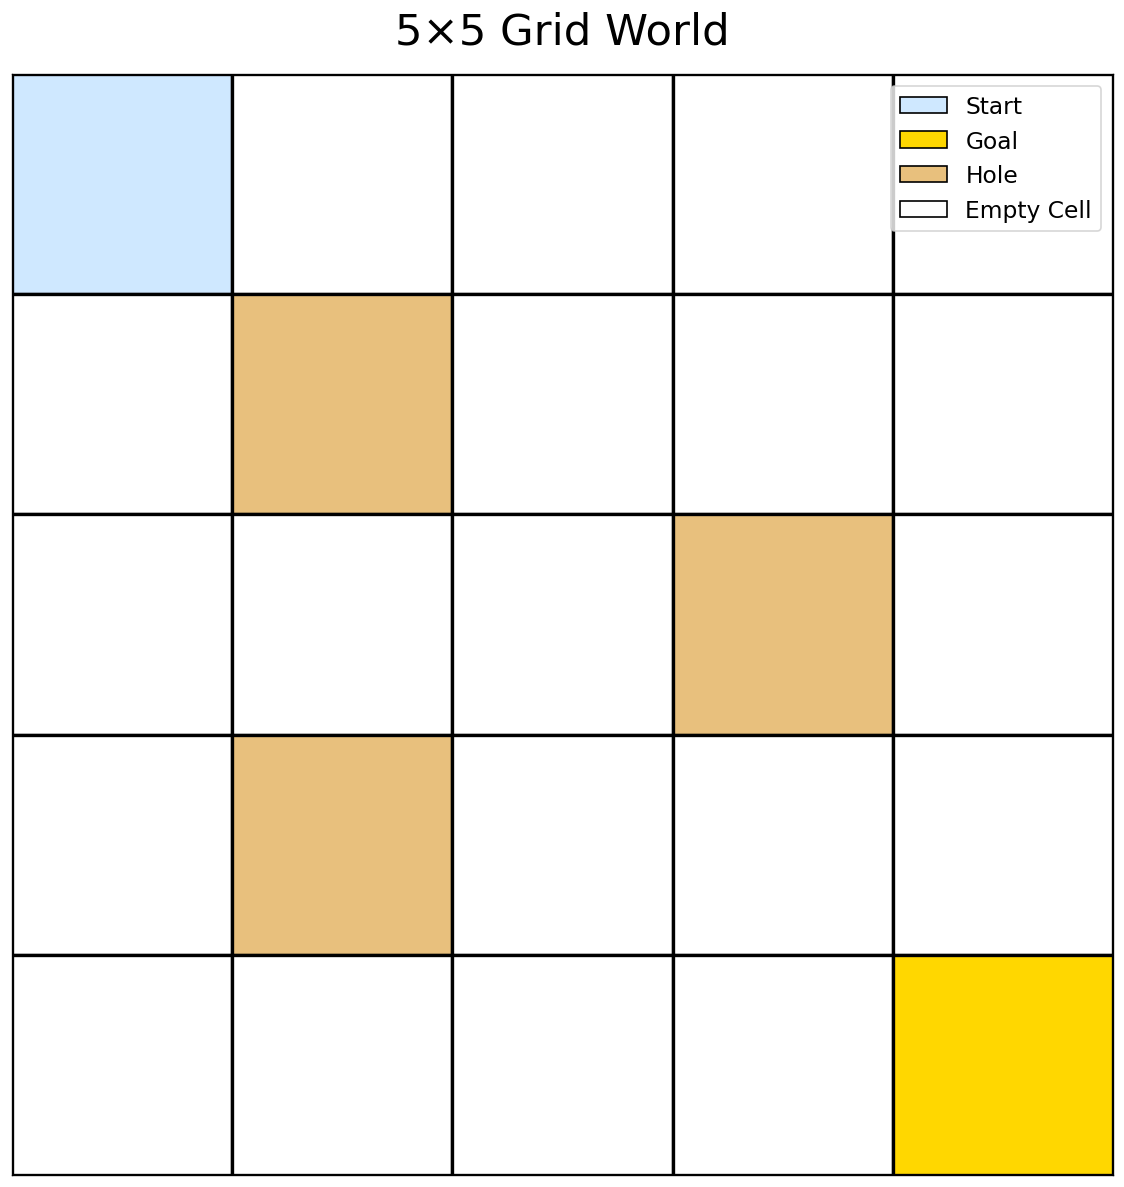

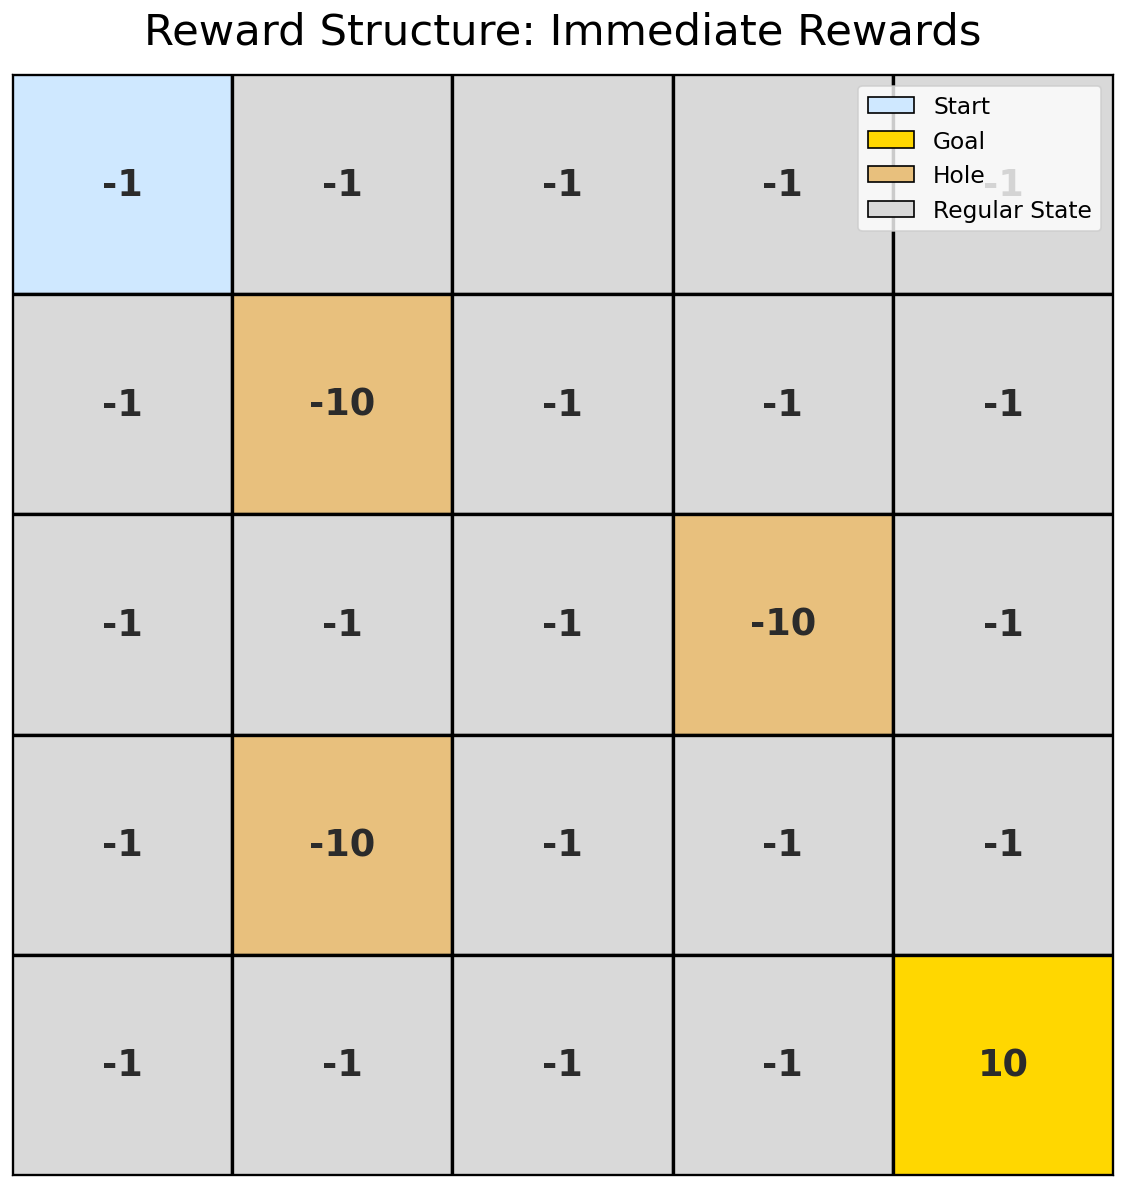

In [2]:
plot_basic_grid_world_figure(
    grid_size=5,
    holes=[(1, 1), (2, 3), (3, 1)],
    start=(0, 0),
    goal=(4, 4),
    save_path=None,
)

plot_reward_structure_figure(
    grid_size=5,
    holes=[(1, 1), (2, 3), (3, 1)],
    start=(0, 0),
    goal=(4, 4),
    step_reward=-1,
    hole_reward=-10,
    goal_reward=10,
    save_path=None,
)

## 1. Basic 4×4 Grid World

In [3]:
env4 = create_grid_world(grid_size=4, transition_noise=0.0)
goal4 = env4.states[-1].id
print(f"States: {len(env4.states)}, Actions: {env4.actions}")

States: 16, Actions: [0, 1, 2, 3]


### Value Iteration

Value iteration converged after 7 iterations
Value Iteration policy: {0: 1, 1: 1, 2: 1, 3: 2, 4: 1, 5: 1, 6: 1, 7: 2, 8: 1, 9: 1, 10: 1, 11: 2, 12: 1, 13: 1, 14: 1, 15: None}


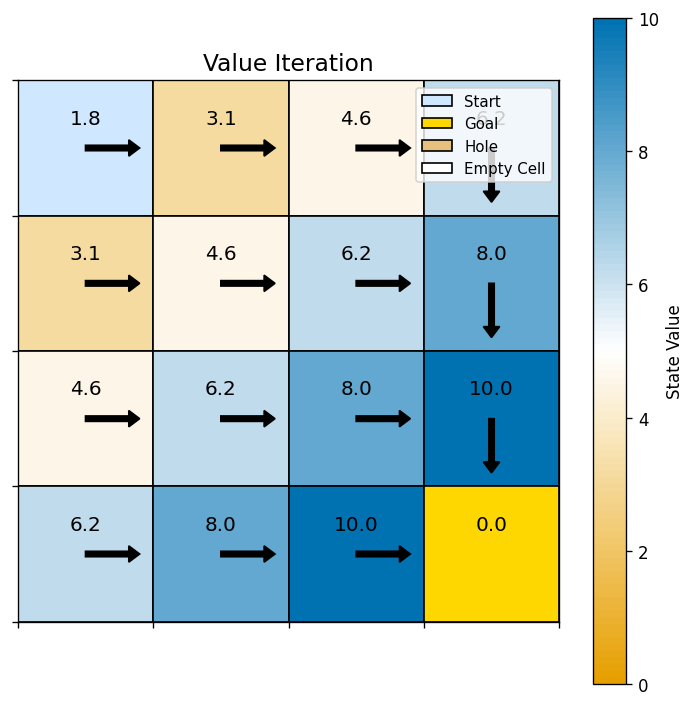

In [4]:
V_vi4 = value_iteration(env4, theta=0.001, max_iterations=100)
pi_vi4 = extract_policy(env4, V_vi4)
print("Value Iteration policy:", pi_vi4)

fig, ax = plt.subplots(figsize=(6, 6))
visualize_grid_world(
    values=V_vi4,
    policy=pi_vi4,
    grid_size=4,
    goal_state=goal4,
    ax=ax,
    title="Value Iteration"
)
plt.tight_layout()
plt.show()

### Policy Iteration

Policy iteration converged after 6 iterations
Policy Iteration policy: {0: 1, 1: 1, 2: 1, 3: 2, 4: 1, 5: 1, 6: 1, 7: 2, 8: 1, 9: 1, 10: 1, 11: 2, 12: 1, 13: 1, 14: 1}


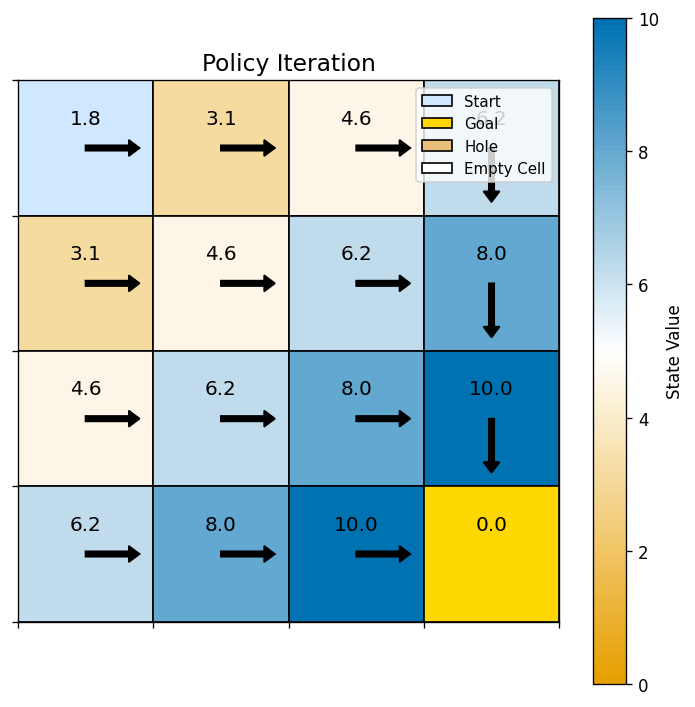

In [5]:
pi_pi4, V_pi4 = policy_iteration(env4, theta=0.001, max_iterations=1000)
print("Policy Iteration policy:", pi_pi4)

fig, ax = plt.subplots(figsize=(6, 6))
visualize_grid_world(
    values=V_pi4,
    policy=pi_pi4,
    grid_size=4,
    goal_state=goal4,
    ax=ax,
    title="Policy Iteration"
)
plt.tight_layout()
plt.show()

### Comparison: Both Algorithms Converge to the Same Optimal Policy

In [6]:
non_terminal4 = [s.id for s in env4.states if not s.terminal]
match4 = all(pi_vi4.get(s) == pi_pi4.get(s) for s in non_terminal4)
max_diff4 = max(abs(V_vi4[s] - V_pi4[s]) for s in non_terminal4)
print(f"Policies match (non-terminal): {match4}")
print(f"Max value difference: {max_diff4:.8f}")

Policies match (non-terminal): True
Max value difference: 0.00000000


## 2. Convergence Analysis

Value Iteration reduces the Bellman error sweep by sweep. Policy Iteration alternates
between evaluating the current policy and performing a greedy improvement step, so a
natural convergence diagnostic is the number of states whose action changes from one
improvement step to the next.

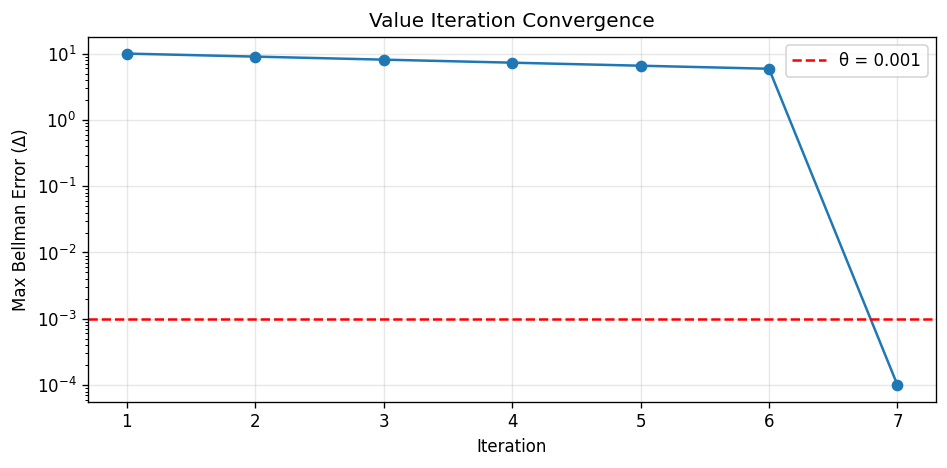

VI converged in 7 iterations


In [8]:
# Trace VI convergence
deltas_vi4, policies_vi4 = value_iteration_trace(env4, theta=0.001)

eps = 0.0001  # small positive floor for log-scale plotting
plot_deltas = [d if d > 0 else eps for d in deltas_vi4]

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(range(1, len(plot_deltas) + 1), plot_deltas, "o-", color="C0")
ax.axhline(0.001, color="red", ls="--", label="θ = 0.001")
ax.set_xlabel("Iteration")
ax.set_ylabel("Max Bellman Error (Δ)")
ax.set_title("Value Iteration Convergence")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"VI converged in {len(deltas_vi4)} iterations")

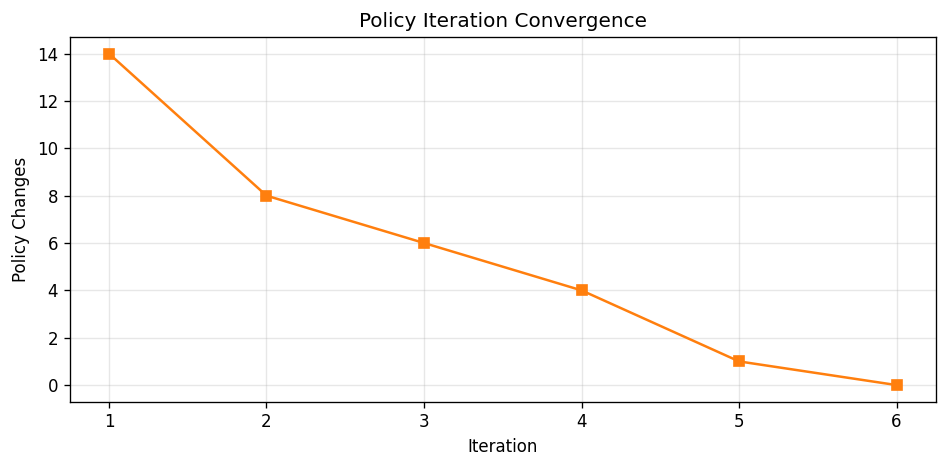

PI converged in 6 iterations


In [9]:
# Trace PI convergence
changes_pi4, policies_pi4 = policy_iteration_trace(env4, theta=0.001)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(changes_pi4) + 1), changes_pi4, "s-", color="C1")
ax.set_xlabel("Iteration")
ax.set_ylabel("Policy Changes")
ax.set_title("Policy Iteration Convergence")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"PI converged in {len(changes_pi4)} iterations")

### Policy Convergence to the Final Solution

In addition to the standard convergence traces, it is useful to check how quickly each
intermediate policy already agrees with the final policy.

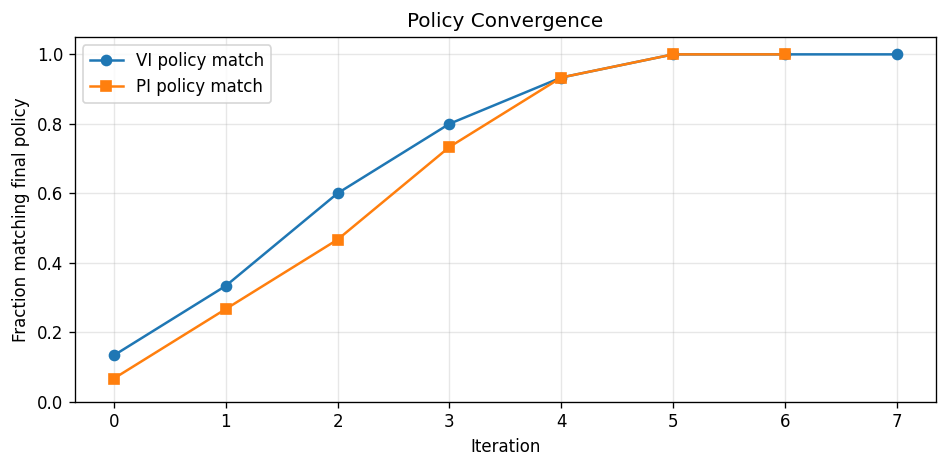

In [10]:
final_vi4 = policies_vi4[-1]
final_pi4 = policies_pi4[-1]

def policy_match(policy, final_policy):
    valid_states = [s for s in final_policy if final_policy[s] is not None]
    return sum(1 for s in valid_states if policy.get(s) == final_policy[s]) / len(valid_states)

match_curve_vi4 = [policy_match(policy, final_vi4) for policy in policies_vi4]
match_curve_pi4 = [policy_match(policy, final_pi4) for policy in policies_pi4]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(len(match_curve_vi4)), match_curve_vi4, "-o", label="VI policy match")
ax.plot(range(len(match_curve_pi4)), match_curve_pi4, "-s", label="PI policy match")
ax.set_xlabel("Iteration")
ax.set_ylabel("Fraction matching final policy")
ax.set_title("Policy Convergence")
ax.set_ylim(0.0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 3. 5×5 Grid with Holes

Adding holes creates a richer planning problem. The optimal policy must route around
terminal penalty states while still reaching the goal efficiently.

Value iteration converged after 9 iterations
Policy iteration converged after 7 iterations


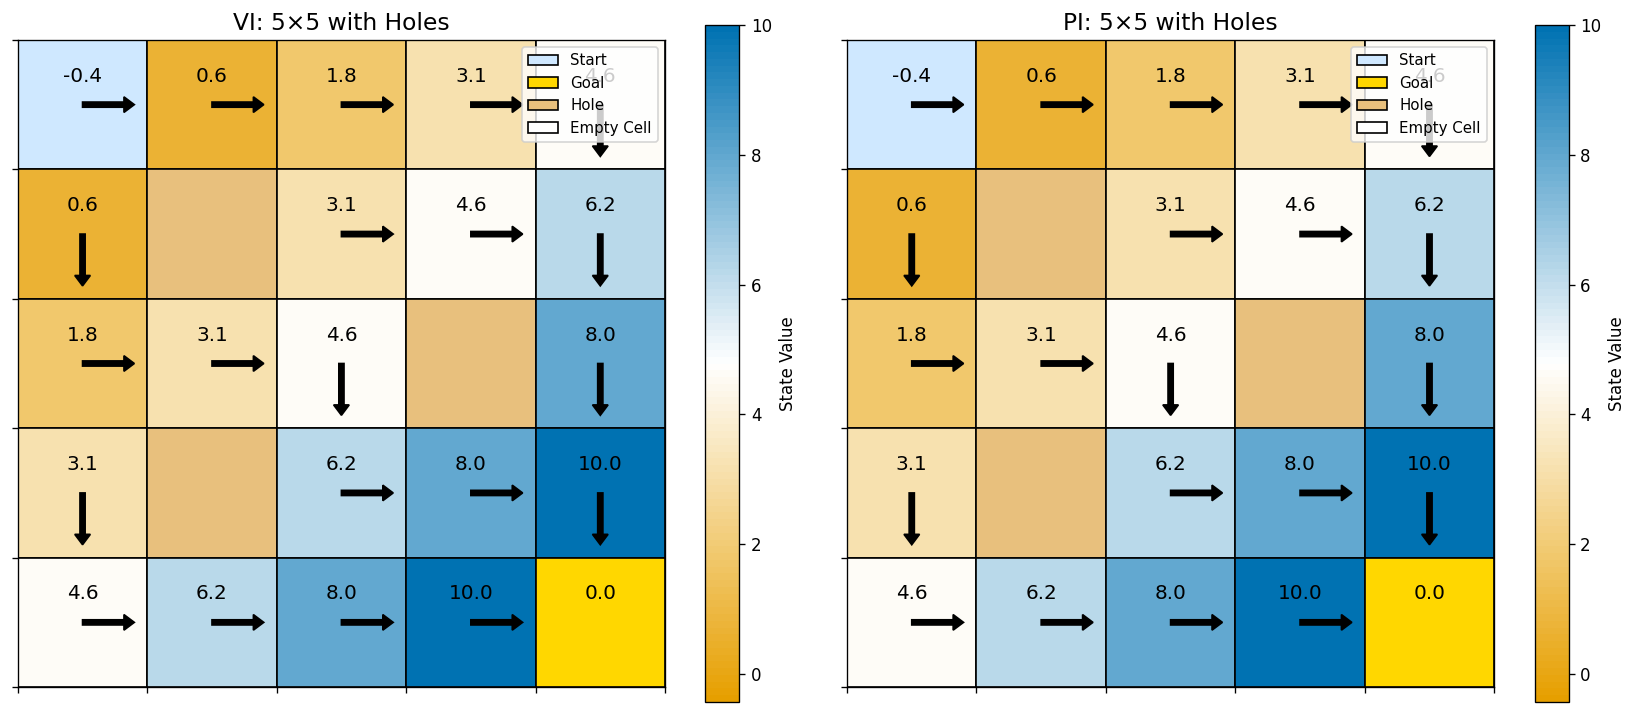

5×5 policies match: True


In [11]:
grid_size = 5
holes = [(1, 1), (2, 3), (3, 1)]
hole_ids = {r * grid_size + c for r, c in holes}

env5 = create_grid_world(grid_size=5, transition_noise=0.0, holes=holes)
goal5 = env5.states[-1].id

V_vi5 = value_iteration(env5, theta=0.001, max_iterations=100)
pi_vi5 = extract_policy(env5, V_vi5)
pi_pi5, V_pi5 = policy_iteration(env5, theta=0.001, max_iterations=1000)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
visualize_grid_world(
    values=V_vi5,
    policy=pi_vi5,
    grid_size=5,
    holes=hole_ids,
    goal_state=goal5,
    ax=axes[0],
    title="VI: 5×5 with Holes",
)
visualize_grid_world(
    values=V_pi5,
    policy=pi_pi5,
    grid_size=5,
    holes=hole_ids,
    goal_state=goal5,
    ax=axes[1],
    title="PI: 5×5 with Holes",
)
plt.tight_layout()
plt.show()

non_terminal5 = [s.id for s in env5.states if not s.terminal]
match5 = all(pi_vi5.get(s) == pi_pi5.get(s) for s in non_terminal5)
print(f"5×5 policies match: {match5}")

### Optimal Value Functions

The updated Chapter 2 notebook added heatmap-style value visualizations, so the
polished version keeps that view while still relying on the helper-file algorithms.

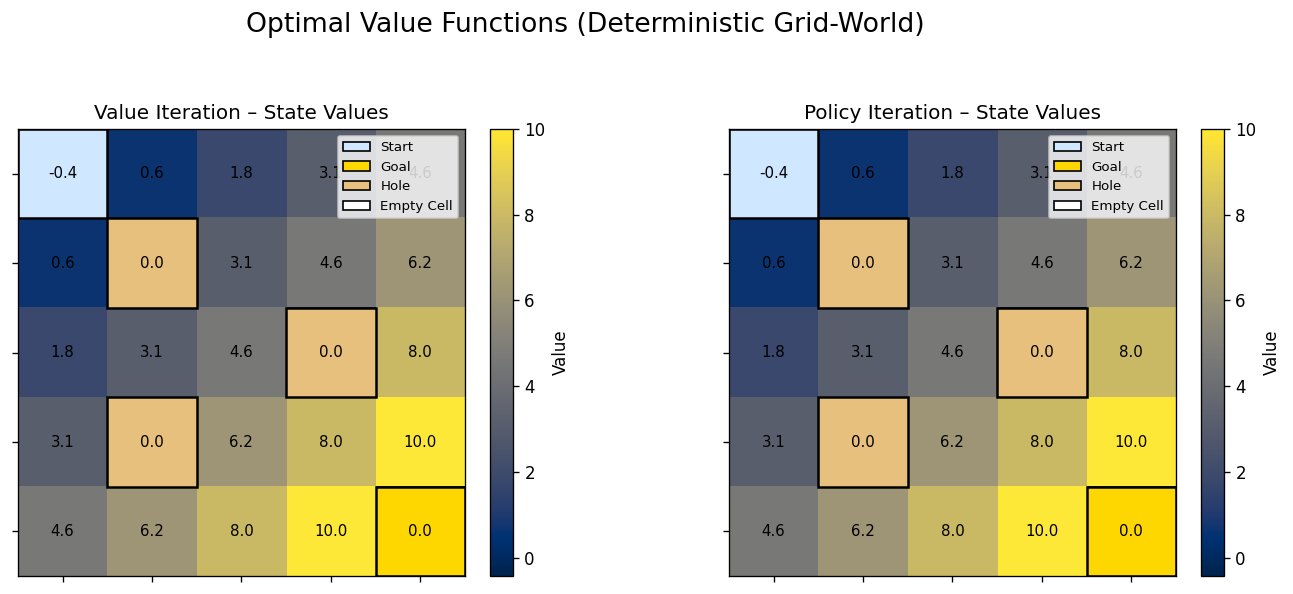

In [12]:
vi_matrix = np.array([V_vi5[s.id] for s in env5.states]).reshape(grid_size, grid_size)
pi_matrix = np.array([V_pi5[s.id] for s in env5.states]).reshape(grid_size, grid_size)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
titles = ["Value Iteration – State Values", "Policy Iteration – State Values"]

for ax, matrix, title in zip(axes, [vi_matrix, pi_matrix], titles):
    im = ax.imshow(matrix, cmap=HEATMAP_CMAP)

    for row in range(grid_size):
        for col in range(grid_size):
            ax.text(
                col,
                row,
                f"{matrix[row, col]:.1f}",
                ha="center",
                va="center",
                fontsize=9,
                color="black",
                zorder=3,
            )

    semantic_states = [(0, START_COLOR), (goal5, GOAL_COLOR)]
    semantic_states.extend((hid, HOLE_COLOR) for hid in sorted(hole_ids))
    for state_id, facecolor in semantic_states:
        row, col = divmod(state_id, grid_size)
        ax.add_patch(
            Rectangle(
                (col - 0.5, row - 0.5),
                1,
                1,
                facecolor=facecolor,
                edgecolor="black",
                linewidth=1.5,
                zorder=2,
            )
        )

    if add_state_legend is not None:
        add_state_legend(
            ax,
            include_regular=True,
            regular_facecolor=OPEN_CELL_COLOR,
            regular_label="Empty Cell",
            fontsize=8,
        )

    ax.set_xticks(range(grid_size))
    ax.set_yticks(range(grid_size))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_title(title)
    ax.grid(False)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Value")

plt.suptitle("Optimal Value Functions (Deterministic Grid-World)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


### Policy Evolution: VI vs PI Step-by-Step

These helper functions let us inspect the policies after a fixed number of sweeps / steps
without redefining any algorithms inside the notebook.

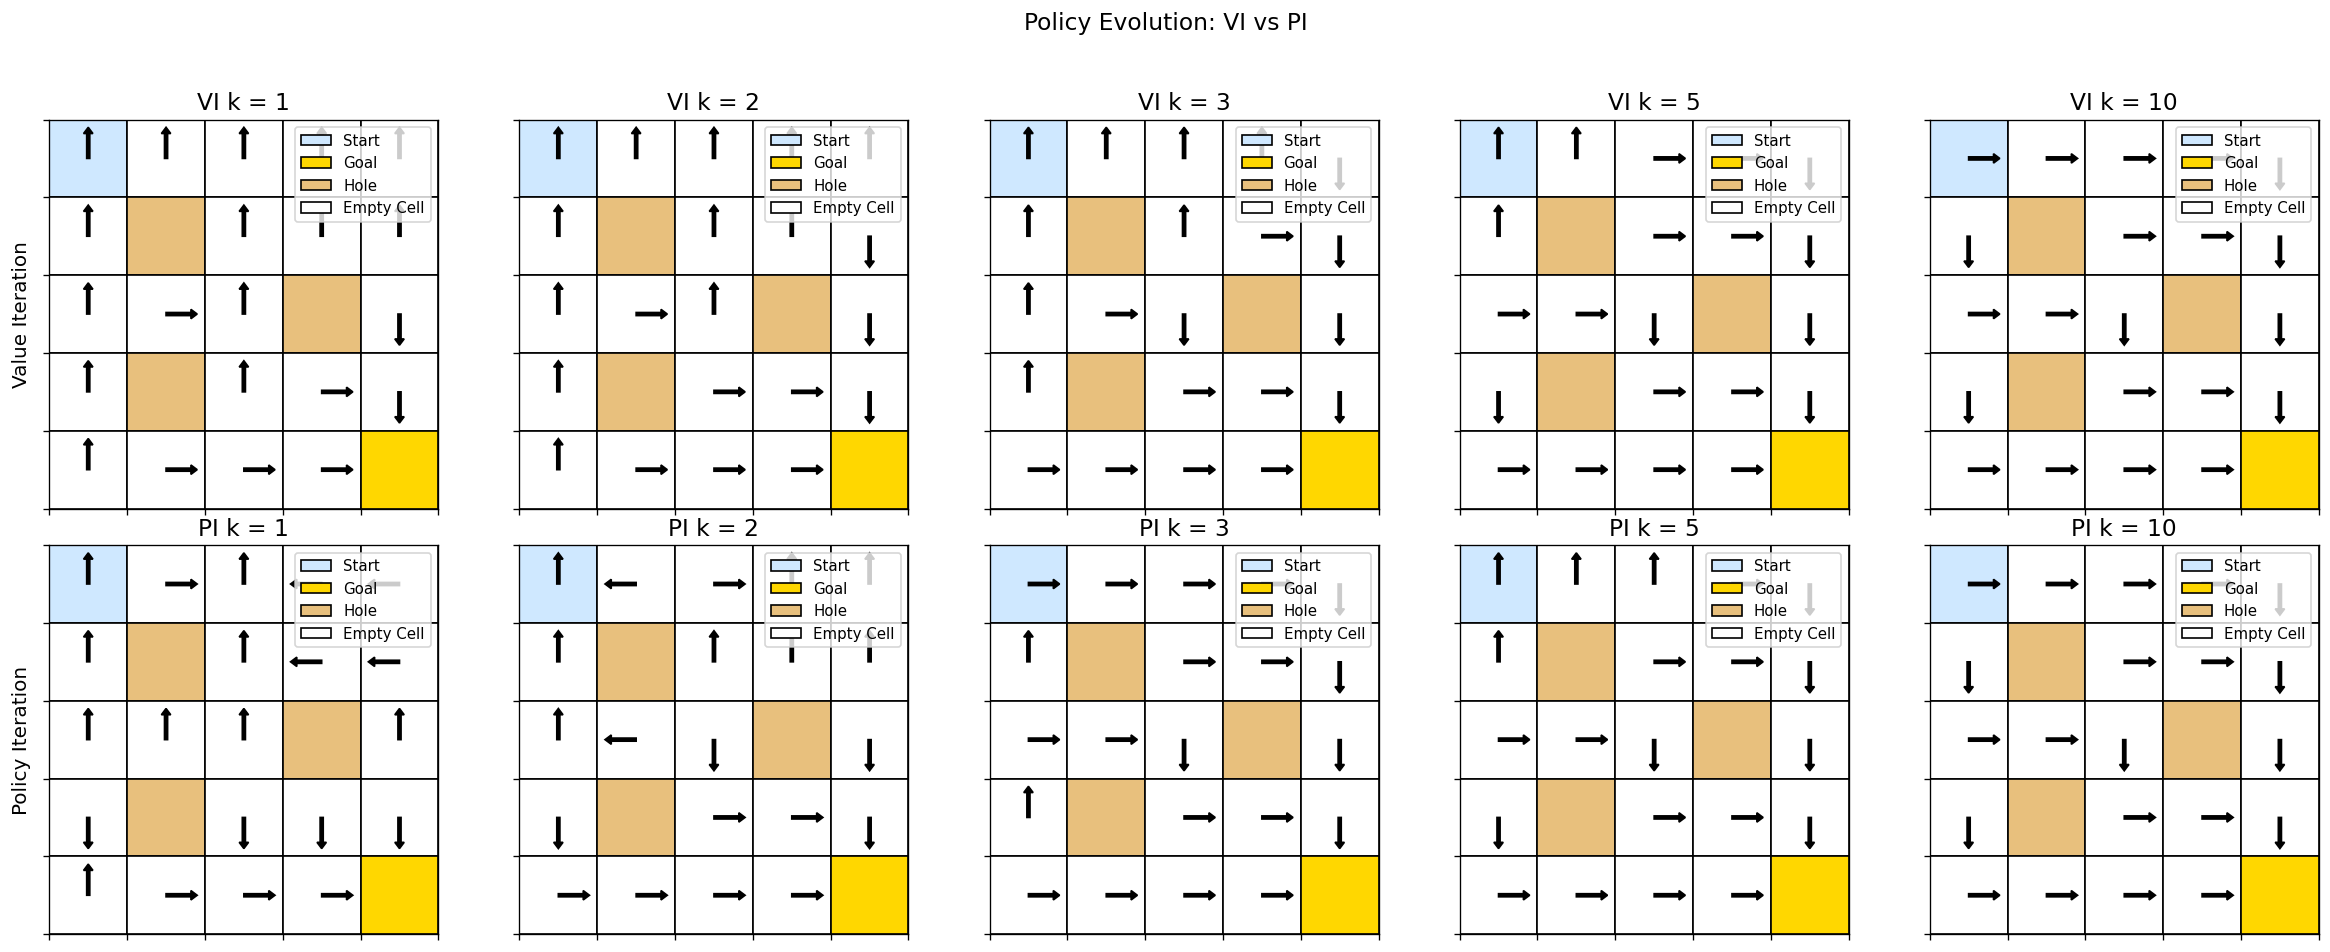

In [13]:
steps_to_show = [1, 2, 3, 5, 10]

fig, axes = plt.subplots(2, len(steps_to_show), figsize=(4 * len(steps_to_show), 8))
for j, k in enumerate(steps_to_show):
    V_k = run_value_iter_steps(env5, k)
    pi_k = extract_policy(env5, V_k)
    visualize_grid_world(
        policy=pi_k,
        grid_size=5,
        holes=hole_ids,
        goal_state=goal5,
        ax=axes[0, j],
        title=f"VI k = {k}",
    )

    pi_k2 = run_policy_iter_steps(env5, k)
    visualize_grid_world(
        policy=pi_k2,
        grid_size=5,
        holes=hole_ids,
        goal_state=goal5,
        ax=axes[1, j],
        title=f"PI k = {k}",
    )

axes[0, 0].set_ylabel("Value Iteration", fontsize=12)
axes[1, 0].set_ylabel("Policy Iteration", fontsize=12)
plt.suptitle("Policy Evolution: VI vs PI", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 4. Agent Evaluation

We compare three agents on the 5×5 grid: the VI-optimal policy, the PI-optimal policy,
and a random walker. Since VI and PI converge to the same policy, their aggregate
performance should closely match.

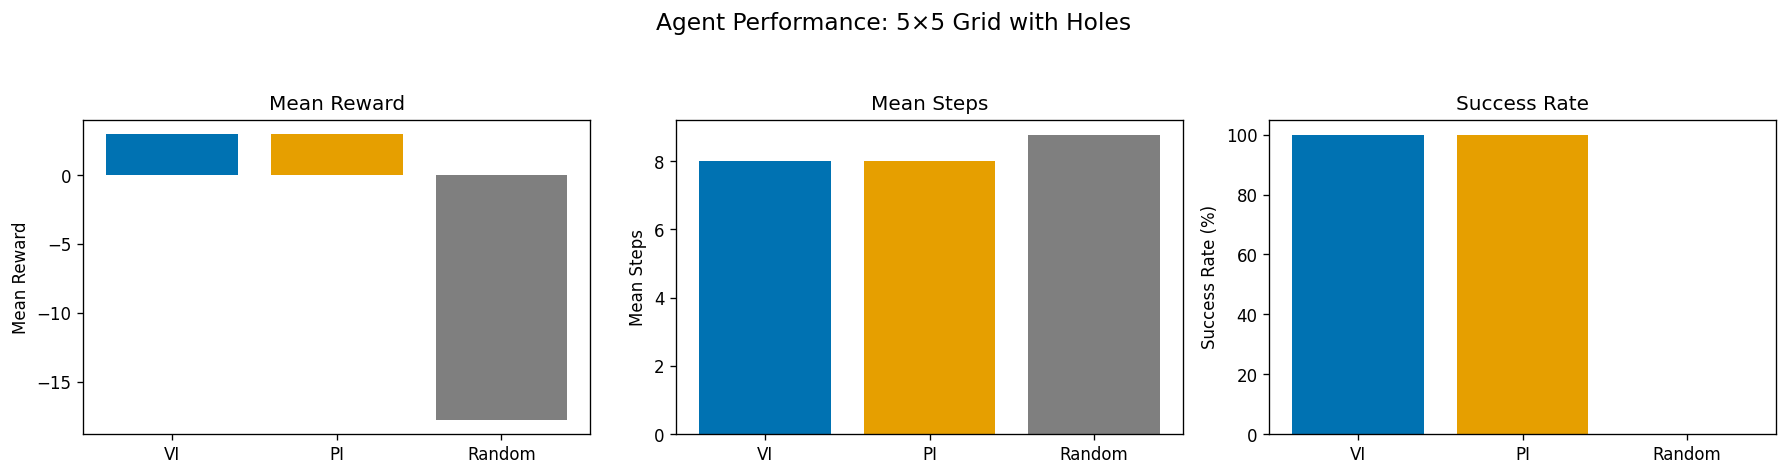

    VI: reward=3.00, steps=8.0, success=100%
    PI: reward=3.00, steps=8.0, success=100%
Random: reward=-17.78, steps=8.8, success=0%


In [15]:
results = {
    "VI": compute_metrics(env5, pi_vi5, num_episodes=100),
    "PI": compute_metrics(env5, pi_pi5, num_episodes=100),
    "Random": compute_metrics(env5, None, num_episodes=100),
}

labels = list(results.keys())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(labels, [results[label]["mean_reward"] for label in labels], color=BAR_COLORS)
axes[0].set_ylabel("Mean Reward")
axes[0].set_title("Mean Reward")

axes[1].bar(labels, [results[label]["mean_steps"] for label in labels], color=BAR_COLORS)
axes[1].set_ylabel("Mean Steps")
axes[1].set_title("Mean Steps")

axes[2].bar(labels, [results[label]["success_rate"] for label in labels], color=BAR_COLORS)
axes[2].set_ylabel("Success Rate (%)")
axes[2].set_title("Success Rate")

plt.suptitle("Agent Performance: 5×5 Grid with Holes", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

for label in labels:
    r = results[label]
    print(
        f"{label:>6}: reward={r['mean_reward']:.2f}, "
        f"steps={r['mean_steps']:.1f}, success={r['success_rate']:.0f}%"
    )

### Agent Path Visualization

Episode: reward=3.00, steps=8, path=[0, 1, 2, 3, 4, 9, 14, 19, 24]


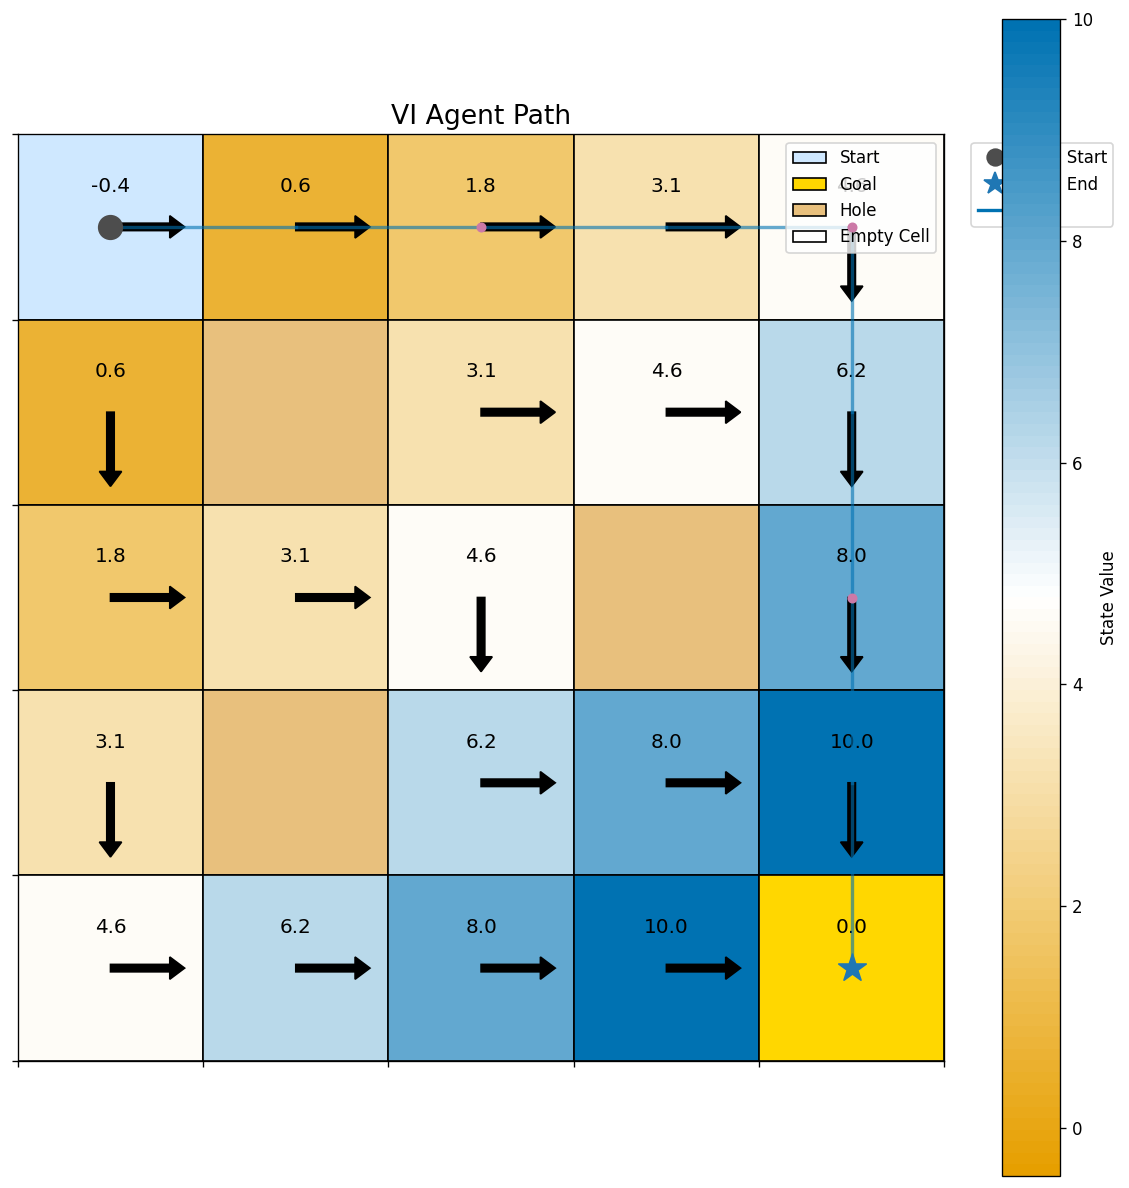

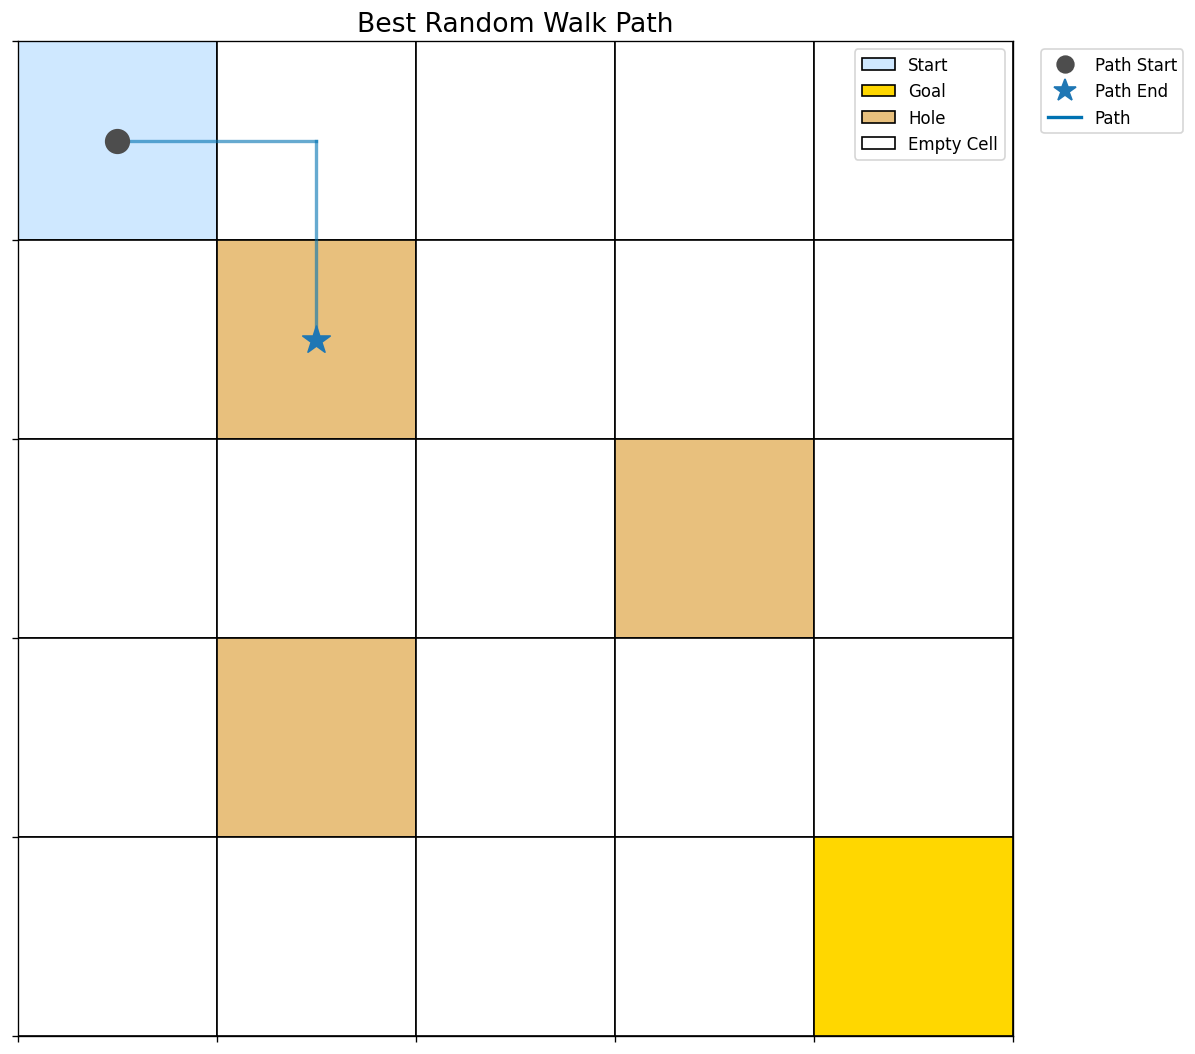

In [16]:
vi_agent = PolicyAgent(env5, pi_vi5)
total_reward, num_steps, path = run_episode(env5, vi_agent, max_steps=100)
print(f"Episode: reward={total_reward:.2f}, steps={num_steps}, path={path}")

# VI path
visualize_agent_path(
    env5,
    path,
    policy=pi_vi5,
    values=V_vi5,
    holes=hole_ids,
    title="VI Agent Path",
)
plt.show()

# Random best path (from SAME results)
random_best_path = results["Random"]["best_path"]

visualize_agent_path(
    env5,
    random_best_path,
    holes=hole_ids,
    title="Best Random Walk Path",
)
plt.show()

## Key Takeaways

Both Value Iteration and Policy Iteration recover the same optimal policy on these
grid worlds. Value Iteration provides a direct view of Bellman-error contraction,
whereas Policy Iteration usually requires fewer improvement steps. On the 5×5 grid with
holes, the optimal behavior clearly routes around penalty states and consistently
outperforms a random walker.